In [ ]:
!pip install -q pandas numpy scikit-learn xgboost mlflow streamlit pyngrok joblib matplotlib seaborn plotly

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 85.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 96.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.2/216.2 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
import joblib
import json

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

# Number of records required by the project
N = 400_000

print("Generating", N, "financial records...")

# -----------------------------
# 1. DEMOGRAPHIC INFORMATION
# -----------------------------

age = np.random.randint(21, 61, N)

gender = np.random.choice(
    ["Male", "Female"],
    N,
    p=[0.55, 0.45]
)

marital_status = np.random.choice(
    ["Single", "Married"],
    N,
    p=[0.42, 0.58]
)

education = np.random.choice(
    ["High School", "Graduate", "Post Graduate", "Professional"],
    N,
    p=[0.20, 0.48, 0.22, 0.10]
)

# -----------------------------
# 2. EMPLOYMENT INFORMATION
# -----------------------------

employment_type = np.random.choice(
    ["Private", "Government", "Self-employed"],
    N,
    p=[0.65, 0.20, 0.15]
)

years_of_employment = np.clip(
    (age - 21) * np.random.uniform(0.35, 0.75, N)
    + np.random.normal(2, 2, N),
    0,
    40
).round(1)

company_type = np.random.choice(
    ["Small", "Medium", "Large", "Government"],
    N,
    p=[0.25, 0.35, 0.25, 0.15]
)

# -----------------------------
# 3. MONTHLY SALARY
# -----------------------------

base_salary = np.random.lognormal(
    mean=np.log(45000),
    sigma=0.55,
    size=N
)

# Salary depends somewhat on employment and experience
salary_multiplier = np.ones(N)

salary_multiplier[employment_type == "Government"] = 1.15
salary_multiplier[employment_type == "Self-employed"] = 1.10
salary_multiplier[company_type == "Large"] *= 1.20
salary_multiplier[company_type == "Small"] *= 0.85

monthly_salary = np.clip(
    base_salary * salary_multiplier,
    15000,
    300000
).round(0)

# -----------------------------
# 4. HOUSING
# -----------------------------

house_type = np.random.choice(
    ["Rented", "Own", "Family"],
    N,
    p=[0.45, 0.35, 0.20]
)

monthly_rent = np.where(
    house_type == "Rented",
    np.random.uniform(5000, 30000, N),
    0
).round(0)

# -----------------------------
# 5. FAMILY INFORMATION
# -----------------------------

family_size = np.random.randint(1, 8, N)

dependents = np.clip(
    family_size - np.random.randint(1, 3, N),
    0,
    6
)

# -----------------------------
# 6. MONTHLY EXPENSES
# -----------------------------

school_fees = np.where(
    dependents > 0,
    np.random.uniform(1000, 15000, N),
    0
).round(0)

college_fees = np.where(
    dependents >= 2,
    np.random.uniform(0, 25000, N),
    np.random.uniform(0, 5000, N)
).round(0)

travel_expenses = np.random.uniform(
    1000, 15000, N
).round(0)

groceries_utilities = (
    family_size * np.random.uniform(2500, 5000, N)
).round(0)

other_monthly_expenses = np.random.uniform(
    1000, 12000, N
).round(0)

# -----------------------------
# 7. EXISTING LOANS / EMI
# -----------------------------

existing_loans = np.random.choice(
    ["Yes", "No"],
    N,
    p=[0.38, 0.62]
)

current_emi_amount = np.where(
    existing_loans == "Yes",
    np.random.uniform(2000, 30000, N),
    0
).round(0)

# -----------------------------
# 8. CREDIT SCORE
# -----------------------------

credit_score = np.clip(
    np.random.normal(700, 70, N),
    300,
    850
).round().astype(int)

# -----------------------------
# 9. BANK BALANCE
# -----------------------------

bank_balance = np.clip(
    monthly_salary * np.random.uniform(1, 8, N),
    5000,
    2000000
).round(0)

# -----------------------------
# 10. EMERGENCY FUND
# -----------------------------

emergency_fund = np.clip(
    monthly_salary * np.random.uniform(0.2, 5, N),
    0,
    1000000
).round(0)

# -----------------------------
# 11. EMI SCENARIO
# -----------------------------

emi_scenario = np.random.choice(
    [
        "E-commerce Shopping EMI",
        "Home Appliances EMI",
        "Vehicle EMI",
        "Personal Loan EMI",
        "Education EMI"
    ],
    N
)

# -----------------------------
# 12. REQUESTED LOAN
# -----------------------------

requested_amount = np.clip(
    monthly_salary * np.random.uniform(2, 25, N),
    10000,
    1500000
).round(0)

requested_tenure = np.random.choice(
    [6, 12, 18, 24, 36, 48, 60, 72, 84],
    N
)

# -----------------------------
# 13. CREATE DATAFRAME
# -----------------------------

df = pd.DataFrame({
    "age": age,
    "gender": gender,
    "marital_status": marital_status,
    "education": education,
    "monthly_salary": monthly_salary,
    "employment_type": employment_type,
    "years_of_employment": years_of_employment,
    "company_type": company_type,
    "house_type": house_type,
    "monthly_rent": monthly_rent,
    "family_size": family_size,
    "dependents": dependents,
    "school_fees": school_fees,
    "college_fees": college_fees,
    "travel_expenses": travel_expenses,
    "groceries_utilities": groceries_utilities,
    "other_monthly_expenses": other_monthly_expenses,
    "existing_loans": existing_loans,
    "current_emi_amount": current_emi_amount,
    "credit_score": credit_score,
    "bank_balance": bank_balance,
    "emergency_fund": emergency_fund,
    "emi_scenario": emi_scenario,
    "requested_amount": requested_amount,
    "requested_tenure": requested_tenure
})

print("Dataset created successfully!")
print("Shape:", df.shape)

Generating 400000 financial records...
Dataset created successfully!
Shape: (400000, 25)


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 400000
Columns: 25


,age,gender,marital_status,education,monthly_salary,employment_type,years_of_employment,company_type,house_type,monthly_rent,...,groceries_utilities,other_monthly_expenses,existing_loans,current_emi_amount,credit_score,bank_balance,emergency_fund,emi_scenario,requested_amount,requested_tenure
0,59,Male,Single,Graduate,22183.0,Private,23.0,Medium,Own,0.0,...,6211.0,8099.0,No,0.0,645,108372.0,71633.0,Education EMI,236309.0,72
1,49,Male,Single,Graduate,43721.0,Private,8.7,Medium,Family,0.0,...,16806.0,4149.0,No,0.0,602,253109.0,157178.0,Personal Loan EMI,952746.0,18
2,35,Female,Married,High School,34928.0,Private,10.5,Small,Own,0.0,...,18794.0,5163.0,Yes,23534.0,633,153030.0,59083.0,Personal Loan EMI,457187.0,36
3,28,Male,Married,Post Graduate,41274.0,Private,5.9,Small,Rented,27377.0,...,27558.0,1196.0,No,0.0,610,225998.0,141738.0,Home Appliances EMI,139408.0,84
4,41,Male,Married,High School,84620.0,Government,11.3,Medium,Family,0.0,...,25460.0,6772.0,No,0.0,631,587826.0,141069.0,Vehicle EMI,1500000.0,48


In [ ]:
print("COLUMN NAMES")
print("=" * 50)

for i, col in enumerate(df.columns, 1):
    print(i, "→", col)


COLUMN NAMES
1 → age
2 → gender
3 → marital_status
4 → education
5 → monthly_salary
6 → employment_type
7 → years_of_employment
8 → company_type
9 → house_type
10 → monthly_rent
11 → family_size
12 → dependents
13 → school_fees
14 → college_fees
15 → travel_expenses
16 → groceries_utilities
17 → other_monthly_expenses
18 → existing_loans
19 → current_emi_amount
20 → credit_score
21 → bank_balance
22 → emergency_fund
23 → emi_scenario
24 → requested_amount
25 → requested_tenure


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   age                     400000 non-null  int64  
 1   gender                  400000 non-null  object 
 2   marital_status          400000 non-null  object 
 3   education               400000 non-null  object 
 4   monthly_salary          400000 non-null  float64
 5   employment_type         400000 non-null  object 
 6   years_of_employment     400000 non-null  float64
 7   company_type            400000 non-null  object 
 8   house_type              400000 non-null  object 
 9   monthly_rent            400000 non-null  float64
 10  family_size             400000 non-null  int64  
 11  dependents              400000 non-null  int64  
 12  school_fees             400000 non-null  float64
 13  college_fees            400000 non-null  float64
 14  travel_expenses     

In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age                       0
gender                    0
marital_status            0
education                 0
monthly_salary            0
employment_type           0
years_of_employment       0
company_type              0
house_type                0
monthly_rent              0
family_size               0
dependents                0
school_fees               0
college_fees              0
travel_expenses           0
groceries_utilities       0
other_monthly_expenses    0
existing_loans            0
current_emi_amount        0
credit_score              0
bank_balance              0
emergency_fund            0
emi_scenario              0
requested_amount          0
requested_tenure          0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
df.to_csv("EMI_dataset.csv", index=False)

print("EMI_dataset.csv saved successfully!")

EMI_dataset.csv saved successfully!


In [ ]:
import os

print(os.path.getsize("EMI_dataset.csv") / (1024 * 1024), "MB")

64.26988124847412 MB


In [ ]:
from google.colab import files

files.download("EMI_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Total monthly expenses

df["total_monthly_expenses"] = (
    df["monthly_rent"]
    + df["school_fees"]
    + df["college_fees"]
    + df["travel_expenses"]
    + df["groceries_utilities"]
    + df["other_monthly_expenses"]
)

# Total current financial obligations

df["total_current_obligations"] = (
    df["total_monthly_expenses"]
    + df["current_emi_amount"]
)

# Disposable income

df["disposable_income"] = (
    df["monthly_salary"]
    - df["total_current_obligations"]
)

# Debt-to-income ratio

df["debt_to_income_ratio"] = (
    df["total_current_obligations"]
    / df["monthly_salary"]
)

print(df[
    [
        "monthly_salary",
        "total_monthly_expenses",
        "current_emi_amount",
        "disposable_income",
        "debt_to_income_ratio"
    ]
].head())

   monthly_salary  total_monthly_expenses  current_emi_amount  \
0         22183.0                 28480.0                 0.0   
1         43721.0                 45000.0                 0.0   
2         34928.0                 61321.0             23534.0   
3         41274.0                 93501.0                 0.0   
4         84620.0                 61459.0                 0.0   

   disposable_income  debt_to_income_ratio  
0            -6297.0              1.283866  
1            -1279.0              1.029254  
2           -49927.0              2.429426  
3           -52227.0              2.265373  
4            23161.0              0.726294  


In [ ]:
# Financial capacity before the new EMI

available_income = (
    df["monthly_salary"] * 0.40
    - df["current_emi_amount"]
    - df["total_monthly_expenses"] * 0.10
)

# Credit-score adjustment
credit_factor = np.where(
    df["credit_score"] >= 750,
    1.10,
    np.where(
        df["credit_score"] >= 650,
        1.00,
        0.80
    )
)

# Emergency fund adjustment
emergency_factor = np.where(
    df["emergency_fund"] >= df["monthly_salary"] * 3,
    1.05,
    0.95
)

max_emi = (
    available_income
    * credit_factor
    * emergency_factor
)

# Keep within the range specified in the project brief
df["max_monthly_emi"] = np.clip(
    max_emi,
    500,
    50000
).round(0)

print(df["max_monthly_emi"].describe())

count    400000.000000
mean      12344.039838
std       12192.454875
min         500.000000
25%        1681.000000
50%        9268.000000
75%       18302.000000
max       50000.000000
Name: max_monthly_emi, dtype: float64


In [ ]:
# Calculate affordability of requested loan

estimated_requested_emi = (
    df["requested_amount"] / df["requested_tenure"]
)

# Risk score
risk_score = (
    (df["credit_score"] < 600).astype(int) * 3
    + (df["debt_to_income_ratio"] > 0.50).astype(int) * 3
    + (df["debt_to_income_ratio"] > 0.35).astype(int) * 2
    + (df["disposable_income"] < 5000).astype(int) * 2
    + (df["existing_loans"] == "Yes").astype(int)
    + (estimated_requested_emi > df["max_monthly_emi"]).astype(int) * 2
)

df["emi_eligibility"] = np.select(
    [
        risk_score <= 2,
        risk_score <= 5
    ],
    [
        "Eligible",
        "High_Risk"
    ],
    default="Not_Eligible"
)

print(df["emi_eligibility"].value_counts())

emi_eligibility
Not_Eligible    323545
High_Risk        47269
Eligible         29186
Name: count, dtype: int64


In [ ]:
print("FINAL DATASET SHAPE")
print(df.shape)

print("\nTARGET 1:")
print(df["emi_eligibility"].value_counts())

print("\nTARGET 2:")
print(df["max_monthly_emi"].describe())

print("\nMISSING VALUES:")
print(df.isnull().sum().sum())

FINAL DATASET SHAPE
(400000, 31)

TARGET 1:
emi_eligibility
Not_Eligible    323545
High_Risk        47269
Eligible         29186
Name: count, dtype: int64

TARGET 2:
count    400000.000000
mean      12344.039838
std       12192.454875
min         500.000000
25%        1681.000000
50%        9268.000000
75%       18302.000000
max       50000.000000
Name: max_monthly_emi, dtype: float64

MISSING VALUES:
0


In [ ]:
df.to_csv("EMI_dataset.csv", index=False)

print("FINAL EMI_dataset.csv saved!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

FINAL EMI_dataset.csv saved!
Rows: 400000
Columns: 31


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Dataset Shape:", df.shape)

Dataset Shape: (400000, 31)


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,400000.0,40.525438,11.548161,21.000000,31.000000,41.000000,51.000000,6.000000e+01
monthly_salary,400000.0,55498.248070,33899.401158,15000.000000,32212.000000,47185.500000,69290.000000,3.000000e+05
years_of_employment,400000.0,12.743114,7.129825,0.000000,7.000000,12.200000,17.800000,3.680000e+01
monthly_rent,400000.0,7876.064280,9962.657369,0.000000,0.000000,0.000000,16119.000000,3.000000e+04
family_size,400000.0,3.996163,1.997226,1.000000,2.000000,4.000000,6.000000,7.000000e+00
dependents,400000.0,2.566485,1.951252,0.000000,1.000000,2.000000,4.000000,6.000000e+00
school_fees,400000.0,6289.137172,4859.333296,0.000000,1634.000000,6103.000000,10554.000000,1.500000e+04
college_fees,400000.0,8913.892075,7560.778482,0.000000,2561.000000,5522.000000,15251.000000,2.500000e+04
travel_expenses,400000.0,7996.586895,4049.685000,1000.000000,4486.000000,7994.000000,11521.000000,1.500000e+04
groceries_utilities,400000.0,14985.783812,8151.289660,2500.000000,8261.000000,14354.000000,20812.000000,3.500000e+04


In [ ]:
print("EMI Eligibility Distribution")
print("=" * 40)

print(df["emi_eligibility"].value_counts())

print("\nPercentage Distribution")
print("=" * 40)

print(
    df["emi_eligibility"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

EMI Eligibility Distribution
emi_eligibility
Not_Eligible    323545
High_Risk        47269
Eligible         29186
Name: count, dtype: int64

Percentage Distribution
emi_eligibility
Not_Eligible    80.89
High_Risk       11.82
Eligible         7.30
Name: proportion, dtype: float64


In [ ]:
print("Current distribution:")
print(df["emi_eligibility"].value_counts())

Current distribution:
emi_eligibility
Not_Eligible    323545
High_Risk        47269
Eligible         29186
Name: count, dtype: int64


In [ ]:
# Create a small continuous variation so that records with similar
# financial risk can still be separated properly.

np.random.seed(42)

risk_index = (
    (df["credit_score"] < 650).astype(int) * 3
    + (df["credit_score"] < 600).astype(int) * 2
    + (df["debt_to_income_ratio"] > 0.35).astype(int) * 2
    + (df["debt_to_income_ratio"] > 0.50).astype(int) * 2
    + (df["disposable_income"] < 10000).astype(int) * 2
    + (df["disposable_income"] < 5000).astype(int) * 2
    + (df["existing_loans"] == "Yes").astype(int)
    + (df["emergency_fund"] < df["monthly_salary"] * 2).astype(int)
    + (df["max_monthly_emi"] < 5000).astype(int)
)

# Add tiny variation to avoid too many identical scores
risk_index = risk_index + np.random.uniform(0, 0.5, len(df))

# Determine boundaries for approximately 40%, 30%, 30%
threshold_40 = np.quantile(risk_index, 0.40)
threshold_70 = np.quantile(risk_index, 0.70)

df["emi_eligibility"] = np.select(
    [
        risk_index <= threshold_40,
        risk_index <= threshold_70
    ],
    [
        "Eligible",
        "High_Risk"
    ],
    default="Not_Eligible"
)

print("New EMI Eligibility Distribution")
print("=" * 40)

print(df["emi_eligibility"].value_counts())

print("\nPercentage Distribution")
print("=" * 40)

print(
    df["emi_eligibility"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

New EMI Eligibility Distribution
emi_eligibility
Eligible        160000
Not_Eligible    120000
High_Risk       120000
Name: count, dtype: int64

Percentage Distribution
emi_eligibility
Eligible        40.0
Not_Eligible    30.0
High_Risk       30.0
Name: proportion, dtype: float64


In [ ]:
df.to_csv("EMI_dataset.csv", index=False)

print("Dataset updated successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset updated successfully!
Rows: 400000
Columns: 31


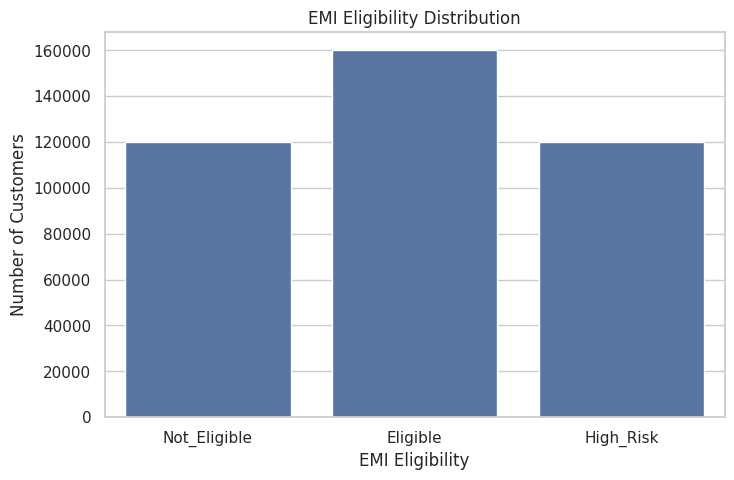

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="emi_eligibility"
)

plt.title("EMI Eligibility Distribution")
plt.xlabel("EMI Eligibility")
plt.ylabel("Number of Customers")

plt.show()

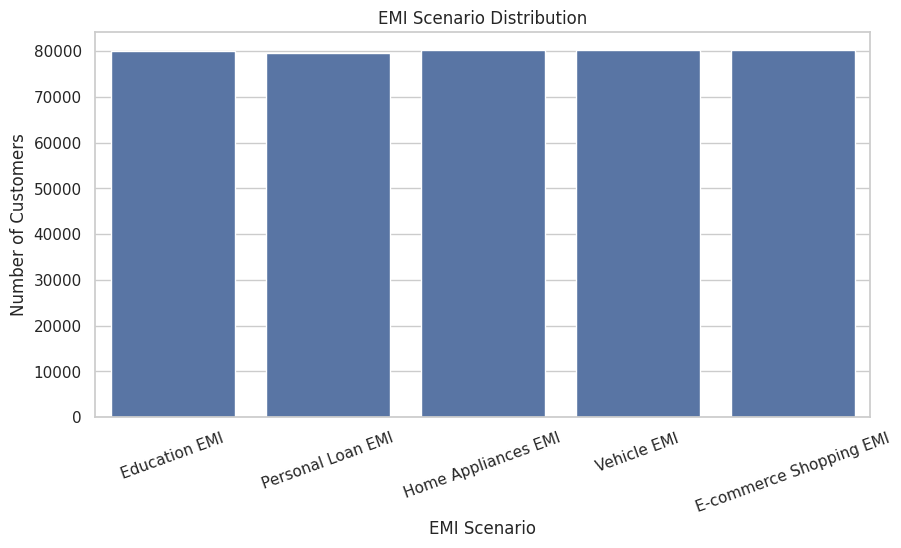

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="emi_scenario"
)

plt.title("EMI Scenario Distribution")
plt.xlabel("EMI Scenario")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

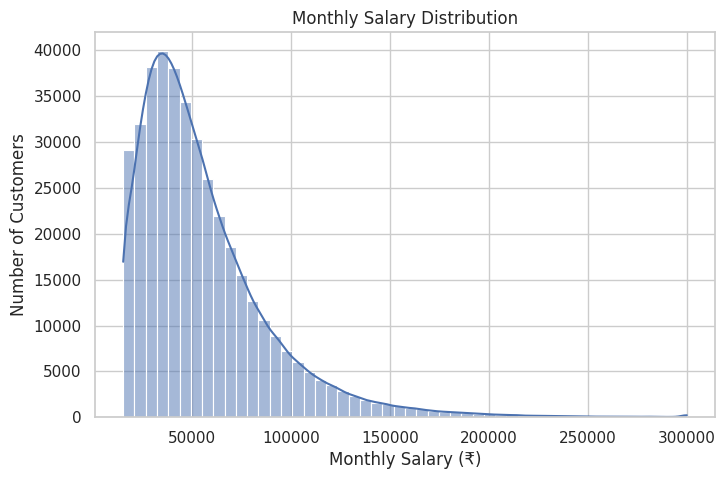

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["monthly_salary"],
    bins=50,
    kde=True
)

plt.title("Monthly Salary Distribution")
plt.xlabel("Monthly Salary (₹)")
plt.ylabel("Number of Customers")

plt.show()

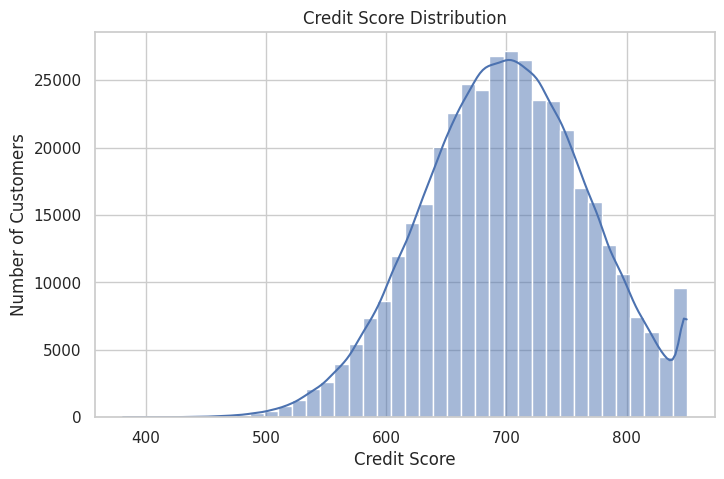

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["credit_score"],
    bins=40,
    kde=True
)

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

plt.show()

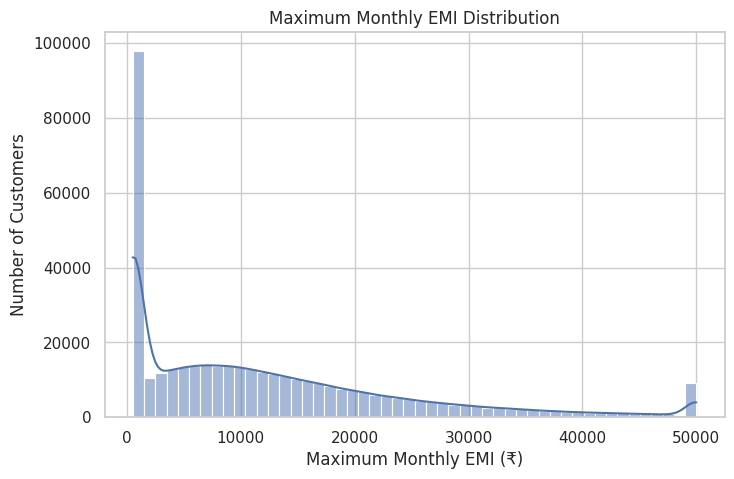

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["max_monthly_emi"],
    bins=50,
    kde=True
)

plt.title("Maximum Monthly EMI Distribution")
plt.xlabel("Maximum Monthly EMI (₹)")
plt.ylabel("Number of Customers")

plt.show()

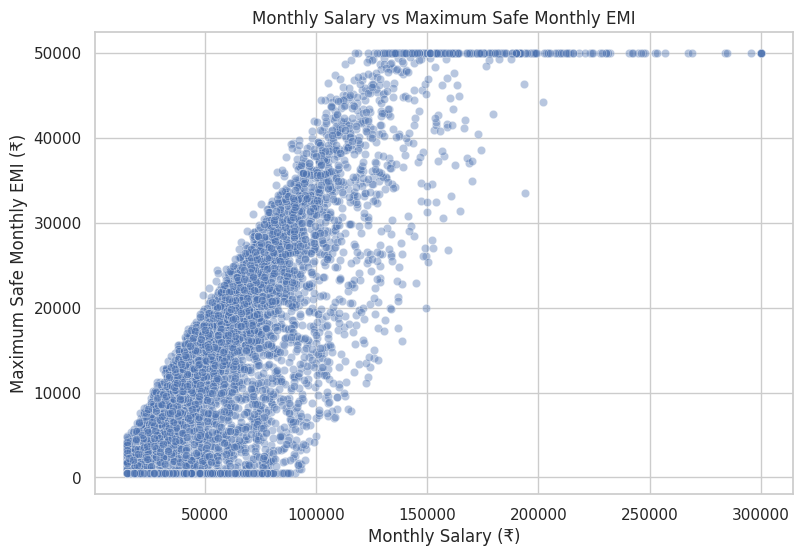

In [ ]:
# Use a sample for faster plotting
sample_df = df.sample(10000, random_state=42)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x="monthly_salary",
    y="max_monthly_emi",
    alpha=0.4
)

plt.title("Monthly Salary vs Maximum Safe Monthly EMI")
plt.xlabel("Monthly Salary (₹)")
plt.ylabel("Maximum Safe Monthly EMI (₹)")

plt.show()

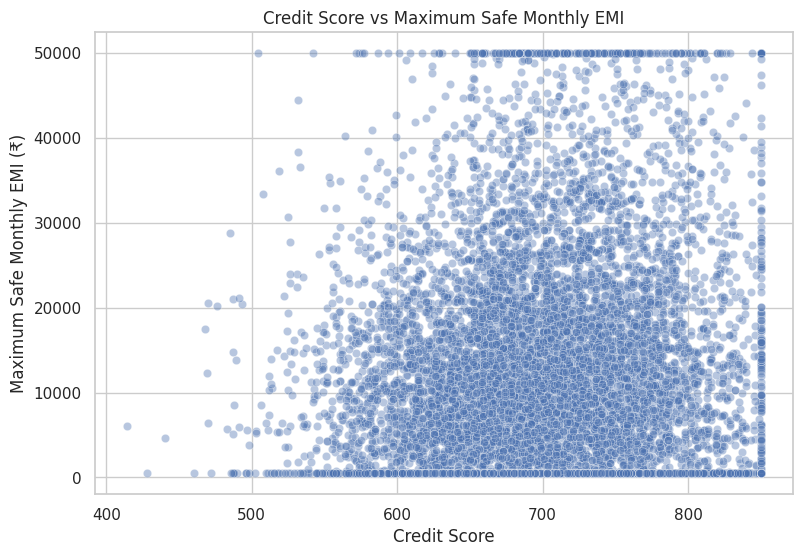

In [ ]:
sample_df = df.sample(10000, random_state=42)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x="credit_score",
    y="max_monthly_emi",
    alpha=0.4
)

plt.title("Credit Score vs Maximum Safe Monthly EMI")
plt.xlabel("Credit Score")
plt.ylabel("Maximum Safe Monthly EMI (₹)")

plt.show()

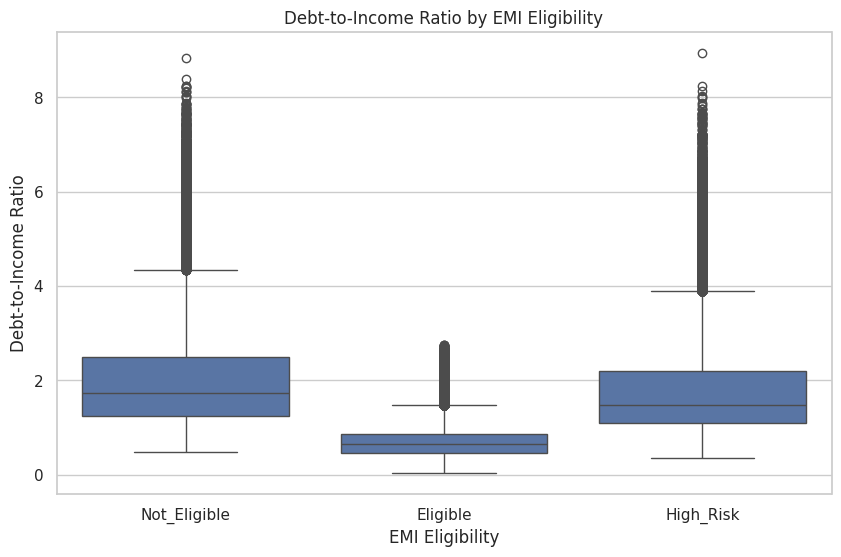

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="debt_to_income_ratio"
)

plt.title("Debt-to-Income Ratio by EMI Eligibility")
plt.xlabel("EMI Eligibility")
plt.ylabel("Debt-to-Income Ratio")

plt.show()

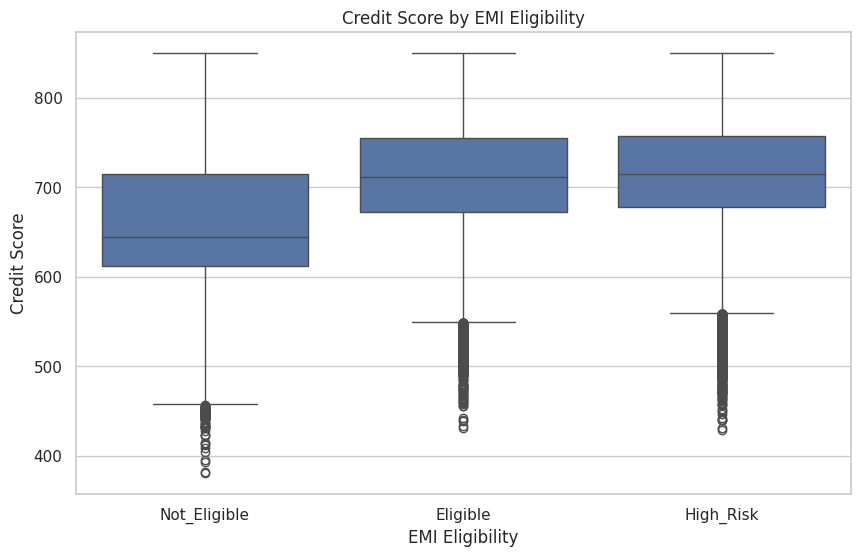

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="credit_score"
)

plt.title("Credit Score by EMI Eligibility")
plt.xlabel("EMI Eligibility")
plt.ylabel("Credit Score")

plt.show()

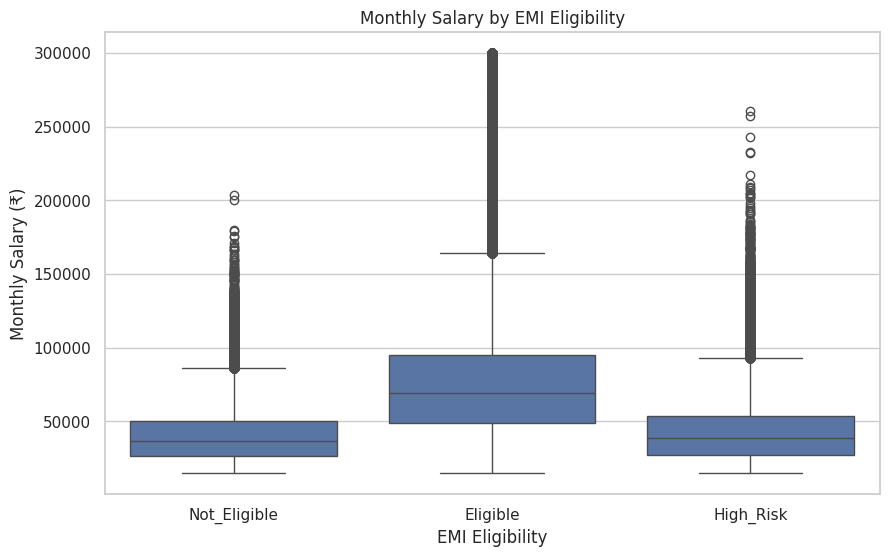

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="emi_eligibility",
    y="monthly_salary"
)

plt.title("Monthly Salary by EMI Eligibility")
plt.xlabel("EMI Eligibility")
plt.ylabel("Monthly Salary (₹)")

plt.show()

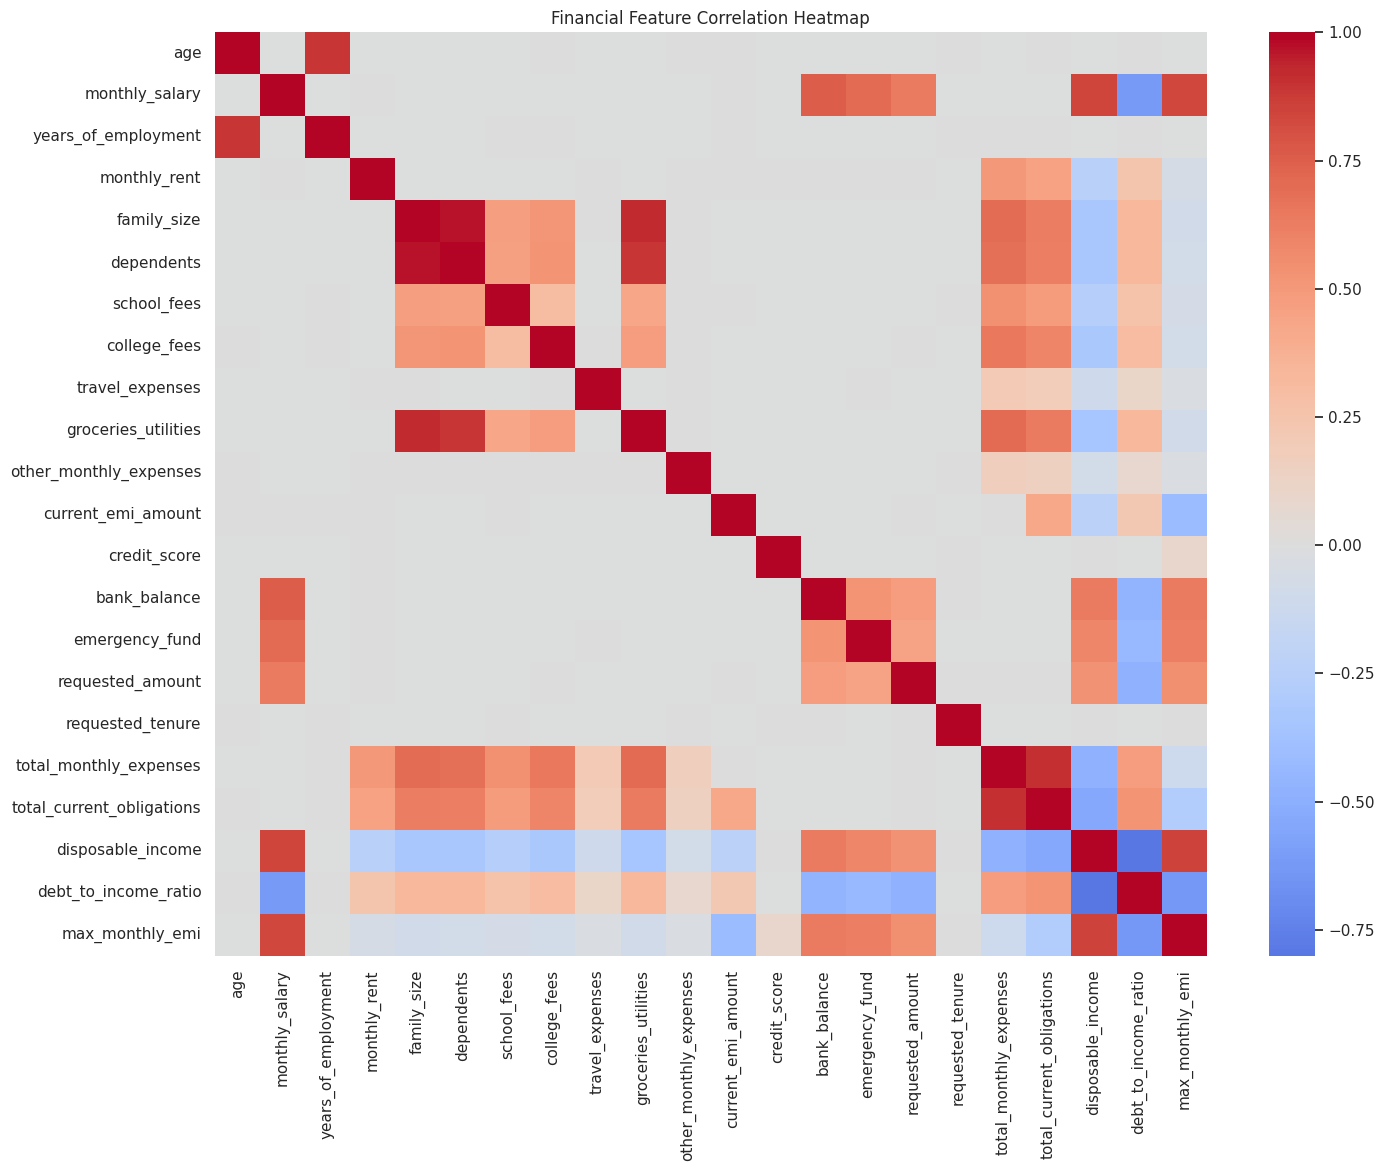

In [ ]:
corr_columns = [
    "age",
    "monthly_salary",
    "years_of_employment",
    "monthly_rent",
    "family_size",
    "dependents",
    "school_fees",
    "college_fees",
    "travel_expenses",
    "groceries_utilities",
    "other_monthly_expenses",
    "current_emi_amount",
    "credit_score",
    "bank_balance",
    "emergency_fund",
    "requested_amount",
    "requested_tenure",
    "total_monthly_expenses",
    "total_current_obligations",
    "disposable_income",
    "debt_to_income_ratio",
    "max_monthly_emi"
]

corr = df[corr_columns].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Financial Feature Correlation Heatmap")
plt.show()

In [ ]:
print("========== FINANCIAL SUMMARY ==========")

print("\nMonthly Salary:")
print(f"Average: ₹{df['monthly_salary'].mean():,.0f}")
print(f"Minimum: ₹{df['monthly_salary'].min():,.0f}")
print(f"Maximum: ₹{df['monthly_salary'].max():,.0f}")

print("\nCredit Score:")
print(f"Average: {df['credit_score'].mean():.0f}")
print(f"Minimum: {df['credit_score'].min()}")
print(f"Maximum: {df['credit_score'].max()}")

print("\nMaximum Safe EMI:")
print(f"Average: ₹{df['max_monthly_emi'].mean():,.0f}")
print(f"Minimum: ₹{df['max_monthly_emi'].min():,.0f}")
print(f"Maximum: ₹{df['max_monthly_emi'].max():,.0f}")

========== FINANCIAL SUMMARY ==========

Monthly Salary:
Average: ₹55,498
Minimum: ₹15,000
Maximum: ₹300,000

Credit Score:
Average: 700
Minimum: 381
Maximum: 850

Maximum Safe EMI:
Average: ₹12,344
Minimum: ₹500
Maximum: ₹50,000


In [ ]:
print("========== EDA CHECK ==========")

print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nEligibility:")
print(df["emi_eligibility"].value_counts())

print("\nEMI Scenarios:")
print(df["emi_scenario"].value_counts())

========== EDA CHECK ==========
Rows: 400,000
Columns: 31
Missing values: 0
Duplicate rows: 0

Eligibility:
emi_eligibility
Eligible        160000
Not_Eligible    120000
High_Risk       120000
Name: count, dtype: int64

EMI Scenarios:
emi_scenario
Home Appliances EMI        80175
E-commerce Shopping EMI    80170
Vehicle EMI                80163
Education EMI              79983
Personal Loan EMI          79509
Name: count, dtype: int64


In [ ]:
classification_target = "emi_eligibility"
regression_target = "max_monthly_emi"

print("Classification Target:", classification_target)
print("Regression Target:", regression_target)

Classification Target: emi_eligibility
Regression Target: max_monthly_emi


In [ ]:
feature_columns = [
    "age",
    "gender",
    "marital_status",
    "education",
    "monthly_salary",
    "employment_type",
    "years_of_employment",
    "company_type",
    "house_type",
    "monthly_rent",
    "family_size",
    "dependents",
    "school_fees",
    "college_fees",
    "travel_expenses",
    "groceries_utilities",
    "other_monthly_expenses",
    "existing_loans",
    "current_emi_amount",
    "credit_score",
    "bank_balance",
    "emergency_fund",
    "emi_scenario",
    "requested_amount",
    "requested_tenure",
    "total_monthly_expenses",
    "total_current_obligations",
    "disposable_income",
    "debt_to_income_ratio"
]

X = df[feature_columns].copy()

y_classification = df["emi_eligibility"].copy()

y_regression = df["max_monthly_emi"].copy()

print("X shape:", X.shape)
print("Classification target:", y_classification.shape)
print("Regression target:", y_regression.shape)

X shape: (400000, 29)
Classification target: (400000,)
Regression target: (400000,)


In [ ]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'marital_status', 'education', 'employment_type', 'company_type', 'house_type', 'existing_loans', 'emi_scenario']

Numerical columns:
['age', 'monthly_salary', 'years_of_employment', 'monthly_rent', 'family_size', 'dependents', 'school_fees', 'college_fees', 'travel_expenses', 'groceries_utilities', 'other_monthly_expenses', 'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund', 'requested_amount', 'requested_tenure', 'total_monthly_expenses', 'total_current_obligations', 'disposable_income', 'debt_to_income_ratio']


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("Classification Training:", X_train_cls.shape)
print("Classification Testing:", X_test_cls.shape)

Classification Training: (320000, 29)
Classification Testing: (80000, 29)


In [ ]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_regression,
    test_size=0.20,
    random_state=42
)

print("Regression Training:", X_train_reg.shape)
print("Regression Testing:", X_test_reg.shape)

Regression Training: (320000, 29)
Regression Testing: (80000, 29)


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

print("Classification libraries imported successfully!")

Classification libraries imported successfully!


In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [ ]:
print("Training Logistic Regression...")

logistic_model.fit(
    X_train_cls,
    y_train_cls
)

print("Logistic Regression training completed!")

Training Logistic Regression...
Logistic Regression training completed!


In [ ]:
y_pred_logistic = logistic_model.predict(X_test_cls)

print("Predictions completed!")
print(y_pred_logistic[:10])

Predictions completed!
['Eligible' 'High_Risk' 'High_Risk' 'High_Risk' 'Eligible' 'Eligible'
 'Not_Eligible' 'Eligible' 'High_Risk' 'Eligible']


In [ ]:
logistic_accuracy = accuracy_score(
    y_test_cls,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test_cls,
    y_pred_logistic,
    average="weighted",
    zero_division=0
)

logistic_recall = recall_score(
    y_test_cls,
    y_pred_logistic,
    average="weighted",
    zero_division=0
)

logistic_f1 = f1_score(
    y_test_cls,
    y_pred_logistic,
    average="weighted",
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test_cls,
    logistic_model.predict_proba(X_test_cls),
    multi_class="ovr",
    average="weighted"
)

print("========== LOGISTIC REGRESSION ==========")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_auc:.4f}")

========== LOGISTIC REGRESSION ==========
Accuracy : 0.7466
Precision: 0.7498
Recall   : 0.7466
F1 Score : 0.7480
ROC-AUC  : 0.9012


In [ ]:
print(classification_report(
    y_test_cls,
    y_pred_logistic,
    zero_division=0
))

              precision    recall  f1-score   support

    Eligible       0.86      0.83      0.84     32000
   High_Risk       0.59      0.61      0.60     24000
Not_Eligible       0.76      0.77      0.77     24000

    accuracy                           0.75     80000
   macro avg       0.74      0.74      0.74     80000
weighted avg       0.75      0.75      0.75     80000



In [ ]:
rf_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                min_samples_split=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [57]:
print("Training Random Forest Classifier...")

rf_classifier.fit(
    X_train_cls,
    y_train_cls
)

print("Random Forest training completed!")

Training Random Forest Classifier...
Random Forest training completed!


In [ ]:
y_pred_rf = rf_classifier.predict(X_test_cls)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [58]:
rf_accuracy = accuracy_score(
    y_test_cls,
    y_pred_rf
)

rf_precision = precision_score(
    y_test_cls,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_recall = recall_score(
    y_test_cls,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_f1 = f1_score(
    y_test_cls,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test_cls,
    rf_classifier.predict_proba(X_test_cls),
    multi_class="ovr",
    average="weighted"
)

print("========== RANDOM FOREST ==========")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_auc:.4f}")

========== RANDOM FOREST ==========
Accuracy : 0.8376
Precision: 0.8413
Recall   : 0.8376
F1 Score : 0.8385
ROC-AUC  : 0.9708


In [59]:
print(classification_report(
    y_test_cls,
    y_pred_rf,
    zero_division=0
))

              precision    recall  f1-score   support

    Eligible       0.93      0.86      0.90     32000
   High_Risk       0.72      0.74      0.73     24000
Not_Eligible       0.84      0.90      0.87     24000

    accuracy                           0.84     80000
   macro avg       0.83      0.83      0.83     80000
weighted avg       0.84      0.84      0.84     80000



In [60]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train_cls)
y_test_xgb = label_encoder.transform(y_test_cls)

print("Class mapping:")
for number, label in enumerate(label_encoder.classes_):
    print(number, "→", label)

Class mapping:
0 → Eligible
1 → High_Risk
2 → Not_Eligible


In [61]:
xgb_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=150,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=3,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost Classifier pipeline created!")

XGBoost Classifier pipeline created!


In [62]:
print("Training XGBoost Classifier...")

xgb_classifier.fit(
    X_train_cls,
    y_train_xgb
)

print("XGBoost training completed!")

Training XGBoost Classifier...
XGBoost training completed!


In [63]:
y_pred_xgb = xgb_classifier.predict(X_test_cls)

print("XGBoost predictions completed!")

XGBoost predictions completed!


In [68]:
# Check XGBoost prediction output

print("y_test_cls type:", type(y_test_cls))
print("Prediction type:", type(y_pred_xgb))

print("First 10 predictions:")
print(y_pred_xgb[:10])

print("Prediction shape:", y_pred_xgb.shape)

y_test_cls type: <class 'pandas.core.series.Series'>
Prediction type: <class 'numpy.ndarray'>
First 10 predictions:
[0 1 1 1 0 0 1 0 1 0]
Prediction shape: (80000,)


In [69]:
# Convert XGBoost predictions to integer labels

y_pred_xgb = np.asarray(y_pred_xgb).astype(int)

y_pred_xgb_labels = label_encoder.inverse_transform(y_pred_xgb)

print("Converted predictions successfully!")
print(y_pred_xgb_labels[:10])

Converted predictions successfully!
['Eligible' 'High_Risk' 'High_Risk' 'High_Risk' 'Eligible' 'Eligible'
 'High_Risk' 'Eligible' 'High_Risk' 'Eligible']


In [70]:
xgb_accuracy = accuracy_score(
    y_test_cls,
    y_pred_xgb_labels
)

print("XGBoost Accuracy:", round(xgb_accuracy, 4))

XGBoost Accuracy: 0.8592


In [72]:
# STEP 15 - Classification Model Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

# ---------- Logistic Regression ----------
log_pred = logistic_model.predict(X_test_cls)
log_prob = logistic_model.predict_proba(X_test_cls)

log_accuracy = accuracy_score(y_test_cls, log_pred)
log_precision = precision_score(
    y_test_cls, log_pred, average="weighted", zero_division=0
)
log_recall = recall_score(
    y_test_cls, log_pred, average="weighted", zero_division=0
)
log_f1 = f1_score(
    y_test_cls, log_pred, average="weighted", zero_division=0
)
log_auc = roc_auc_score(
    y_test_cls,
    log_prob,
    multi_class="ovr",
    average="weighted"
)

# ---------- Random Forest ----------
rf_pred = rf_classifier.predict(X_test_cls)
rf_prob = rf_classifier.predict_proba(X_test_cls)

rf_accuracy = accuracy_score(y_test_cls, rf_pred)
rf_precision = precision_score(
    y_test_cls, rf_pred, average="weighted", zero_division=0
)
rf_recall = recall_score(
    y_test_cls, rf_pred, average="weighted", zero_division=0
)
rf_f1 = f1_score(
    y_test_cls, rf_pred, average="weighted", zero_division=0
)
rf_auc = roc_auc_score(
    y_test_cls,
    rf_prob,
    multi_class="ovr",
    average="weighted"
)

# ---------- XGBoost ----------
xgb_pred_numbers = xgb_classifier.predict(X_test_cls)
xgb_pred_numbers = np.asarray(xgb_pred_numbers).astype(int)

xgb_pred = label_encoder.inverse_transform(xgb_pred_numbers)
xgb_prob = xgb_classifier.predict_proba(X_test_cls)

xgb_accuracy = accuracy_score(y_test_cls, xgb_pred)
xgb_precision = precision_score(
    y_test_cls, xgb_pred, average="weighted", zero_division=0
)
xgb_recall = recall_score(
    y_test_cls, xgb_pred, average="weighted", zero_division=0
)
xgb_f1 = f1_score(
    y_test_cls, xgb_pred, average="weighted", zero_division=0
)
xgb_auc = roc_auc_score(
    y_test_xgb,
    xgb_prob,
    multi_class="ovr",
    average="weighted"
)

# ---------- Comparison Table ----------
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        log_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        log_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        log_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        log_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        log_auc,
        rf_auc,
        xgb_auc
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.746637,0.749849,0.746637,0.748032,0.901207
1,Random Forest,0.837562,0.841305,0.837562,0.838494,0.970762
2,XGBoost,0.859250,0.859510,0.859250,0.857813,0.974656


In [73]:
best_classification = classification_results.loc[
    classification_results["F1 Score"].idxmax()
]

print("BEST CLASSIFICATION MODEL")
print("=" * 40)
print("Model:", best_classification["Model"])
print("Accuracy:", round(best_classification["Accuracy"], 4))
print("Precision:", round(best_classification["Precision"], 4))
print("Recall:", round(best_classification["Recall"], 4))
print("F1 Score:", round(best_classification["F1 Score"], 4))
print("ROC-AUC:", round(best_classification["ROC-AUC"], 4))

BEST CLASSIFICATION MODEL
Model: XGBoost
Accuracy: 0.8592
Precision: 0.8595
Recall: 0.8592
F1 Score: 0.8578
ROC-AUC: 0.9747


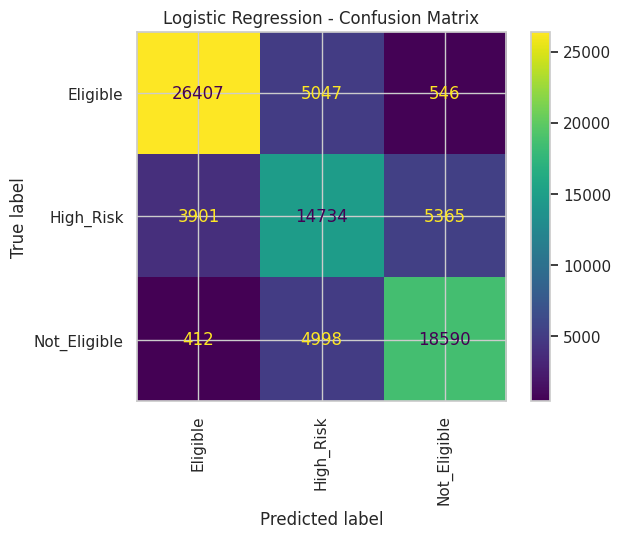

In [74]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    log_pred,
    xticks_rotation="vertical"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

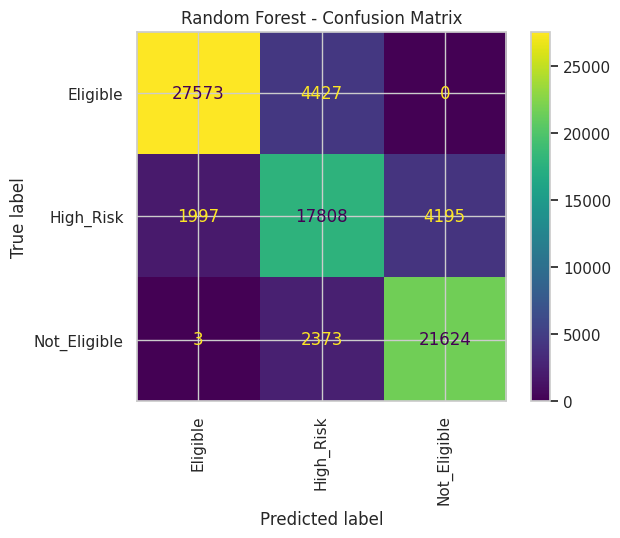

In [75]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    rf_pred,
    xticks_rotation="vertical"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

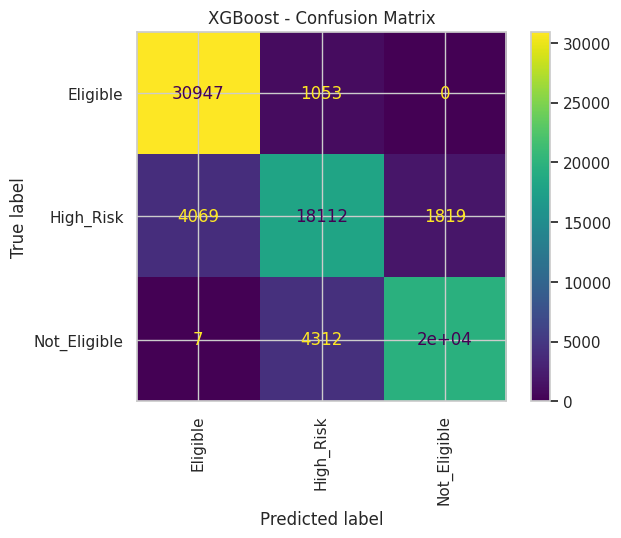

In [76]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls,
    xgb_pred,
    xticks_rotation="vertical"
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

In [77]:
classification_results.to_csv(
    "classification_results.csv",
    index=False
)

print("Classification results saved successfully!")

Classification results saved successfully!


In [78]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBRegressor

print("Regression libraries imported successfully!")

Regression libraries imported successfully!


In [79]:
def calculate_mape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    denominator = np.where(
        y_true == 0,
        1,
        y_true
    )

    return np.mean(
        np.abs((y_true - y_pred) / denominator)
    ) * 100

print("MAPE function created!")

MAPE function created!


In [80]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression pipeline created!")

Linear Regression pipeline created!


In [81]:
print("Training Linear Regression...")

linear_model.fit(
    X_train_reg,
    y_train_reg
)

print("Linear Regression training completed!")

Training Linear Regression...
Linear Regression training completed!


In [82]:
linear_pred = linear_model.predict(X_test_reg)

print("Predictions completed!")
print(linear_pred[:10])

Predictions completed!
[ 7732.05186523 10898.56236752 10575.56645524 -3053.78722
 13297.5031977  77188.0022463   7700.005923   -5187.52922451
 10555.15305375  8735.94956829]


In [83]:
linear_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        linear_pred
    )
)

linear_mae = mean_absolute_error(
    y_test_reg,
    linear_pred
)

linear_r2 = r2_score(
    y_test_reg,
    linear_pred
)

linear_mape = calculate_mape(
    y_test_reg,
    linear_pred
)

print("========== LINEAR REGRESSION ==========")
print("RMSE :", round(linear_rmse, 2))
print("MAE  :", round(linear_mae, 2))
print("R²   :", round(linear_r2, 4))
print("MAPE :", round(linear_mape, 2), "%")


========== LINEAR REGRESSION ==========
RMSE : 3704.92
MAE  : 2647.4
R²   : 0.9071
MAPE : 183.47 %


In [84]:
rf_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_split=10,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest Regressor created!")

Random Forest Regressor created!


In [85]:
print("Training Random Forest Regressor...")

rf_regressor.fit(
    X_train_reg,
    y_train_reg
)

print("Random Forest Regressor training completed!")

Training Random Forest Regressor...
Random Forest Regressor training completed!


In [86]:
rf_reg_pred = rf_regressor.predict(X_test_reg)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [87]:
rf_reg_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        rf_reg_pred
    )
)

rf_reg_mae = mean_absolute_error(
    y_test_reg,
    rf_reg_pred
)

rf_reg_r2 = r2_score(
    y_test_reg,
    rf_reg_pred
)

rf_reg_mape = calculate_mape(
    y_test_reg,
    rf_reg_pred
)

print("========== RANDOM FOREST REGRESSOR ==========")
print("RMSE :", round(rf_reg_rmse, 2))
print("MAE  :", round(rf_reg_mae, 2))
print("R²   :", round(rf_reg_r2, 4))
print("MAPE :", round(rf_reg_mape, 2), "%")

========== RANDOM FOREST REGRESSOR ==========
RMSE : 354.07
MAE  : 157.48
R²   : 0.9992
MAPE : 2.0 %


In [88]:
xgb_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                n_estimators=150,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                eval_metric="rmse",
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost Regressor created!")

XGBoost Regressor created!


In [89]:
print("Training XGBoost Regressor...")

xgb_regressor.fit(
    X_train_reg,
    y_train_reg
)

print("XGBoost Regressor training completed!")

Training XGBoost Regressor...
XGBoost Regressor training completed!


In [90]:
xgb_reg_pred = xgb_regressor.predict(
    X_test_reg
)

print("XGBoost predictions completed!")
print(xgb_reg_pred[:10])

XGBoost predictions completed!
[ 4853.4126  12103.421   12304.733     525.5537  12114.687   49559.848
  4972.629     477.89355 10878.683    8199.165  ]


In [91]:
xgb_reg_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        xgb_reg_pred
    )
)

xgb_reg_mae = mean_absolute_error(
    y_test_reg,
    xgb_reg_pred
)

xgb_reg_r2 = r2_score(
    y_test_reg,
    xgb_reg_pred
)

xgb_reg_mape = calculate_mape(
    y_test_reg,
    xgb_reg_pred
)

print("========== XGBOOST REGRESSOR ==========")
print("RMSE :", round(xgb_reg_rmse, 2))
print("MAE  :", round(xgb_reg_mae, 2))
print("R²   :", round(xgb_reg_r2, 4))
print("MAPE :", round(xgb_reg_mape, 2), "%")

========== XGBOOST REGRESSOR ==========
RMSE : 403.51
MAE  : 259.28
R²   : 0.9989
MAPE : 7.45 %


In [92]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regressor",
        "XGBoost Regressor"
    ],
    "RMSE": [
        linear_rmse,
        rf_reg_rmse,
        xgb_reg_rmse
    ],
    "MAE": [
        linear_mae,
        rf_reg_mae,
        xgb_reg_mae
    ],
    "R2": [
        linear_r2,
        rf_reg_r2,
        xgb_reg_r2
    ],
    "MAPE": [
        linear_mape,
        rf_reg_mape,
        xgb_reg_mape
    ]
})

regression_results

,Model,RMSE,MAE,R2,MAPE
0,Linear Regression,3704.919610,2647.402279,0.907120,183.466458
1,Random Forest Regressor,354.065475,157.476675,0.999152,2.001457
2,XGBoost Regressor,403.510414,259.283949,0.998898,7.454202


In [93]:
best_regression = regression_results.loc[
    regression_results["RMSE"].idxmin()
]

print("BEST REGRESSION MODEL")
print("=" * 40)
print("Model:", best_regression["Model"])
print("RMSE:", round(best_regression["RMSE"], 2))
print("MAE:", round(best_regression["MAE"], 2))
print("R²:", round(best_regression["R2"], 4))
print("MAPE:", round(best_regression["MAPE"], 2), "%")

BEST REGRESSION MODEL
Model: Random Forest Regressor
RMSE: 354.07
MAE: 157.48
R²: 0.9992
MAPE: 2.0 %


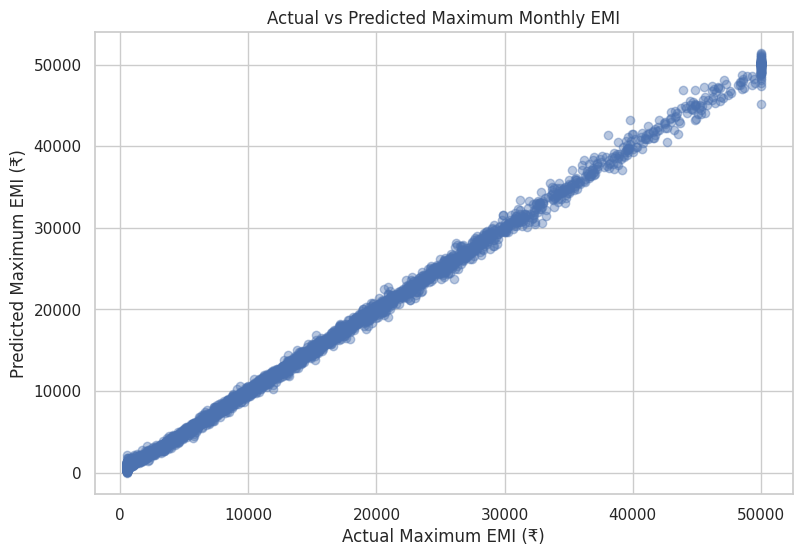

In [94]:
sample_indices = np.random.choice(
    len(y_test_reg),
    size=5000,
    replace=False
)

actual_sample = np.asarray(
    y_test_reg
)[sample_indices]

predicted_sample = np.asarray(
    xgb_reg_pred
)[sample_indices]

plt.figure(figsize=(9, 6))

plt.scatter(
    actual_sample,
    predicted_sample,
    alpha=0.4
)

plt.xlabel("Actual Maximum EMI (₹)")
plt.ylabel("Predicted Maximum EMI (₹)")
plt.title("Actual vs Predicted Maximum Monthly EMI")

plt.show()

In [95]:
regression_results.to_csv(
    "regression_results.csv",
    index=False
)

print("Regression results saved successfully!")

Regression results saved successfully!


In [96]:
import joblib

joblib.dump(
    logistic_model,
    "logistic_regression_model.pkl"
)

joblib.dump(
    rf_classifier,
    "random_forest_classifier.pkl"
)

joblib.dump(
    xgb_classifier,
    "xgboost_classifier.pkl"
)

joblib.dump(
    linear_model,
    "linear_regression_model.pkl"
)

joblib.dump(
    rf_regressor,
    "random_forest_regressor.pkl"
)

joblib.dump(
    xgb_regressor,
    "xgboost_regressor.pkl"
)

joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)

print("All six ML models saved successfully!")

All six ML models saved successfully!


In [97]:
import os

model_files = [
    "logistic_regression_model.pkl",
    "random_forest_classifier.pkl",
    "xgboost_classifier.pkl",
    "linear_regression_model.pkl",
    "random_forest_regressor.pkl",
    "xgboost_regressor.pkl",
    "label_encoder.pkl"
]

for file in model_files:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗", file)

✓ logistic_regression_model.pkl
✓ random_forest_classifier.pkl
✓ xgboost_classifier.pkl
✓ linear_regression_model.pkl
✓ random_forest_regressor.pkl
✓ xgboost_regressor.pkl
✓ label_encoder.pkl


In [98]:
import os

os.makedirs("EMIPredict_Project", exist_ok=True)

# Copy important files
import shutil

files_to_copy = [
    "EMI_dataset.csv",
    "classification_results.csv",
    "regression_results.csv",
    "logistic_regression_model.pkl",
    "random_forest_classifier.pkl",
    "xgboost_classifier.pkl",
    "linear_regression_model.pkl",
    "random_forest_regressor.pkl",
    "xgboost_regressor.pkl",
    "label_encoder.pkl"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(
            file,
            "EMIPredict_Project/" + file
        )

print("Project files organized successfully!")

Project files organized successfully!


In [99]:
!pip install -q mlflow

In [100]:
import mlflow
import mlflow.sklearn

print("MLflow version:", mlflow.__version__)

MLflow version: 3.15.1


In [101]:
mlflow.set_experiment("EMI_Predictor_Experiments")

print("MLflow experiment created successfully!")

2026/08/18 15:41:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/18 15:41:28 INFO mlflow.store.db.utils: Updating database tables
2026/08/18 15:41:33 INFO mlflow.tracking.fluent: Experiment with name 'EMI_Predictor_Experiments' does not exist. Creating a new experiment.


MLflow experiment created successfully!


In [103]:
# STEP 41 - Track Logistic Regression in MLflow

with mlflow.start_run(run_name="Logistic_Regression_Classification"):

    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("task", "Classification")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("class_weight", "balanced")

    mlflow.log_metric("accuracy", float(log_accuracy))
    mlflow.log_metric("precision", float(log_precision))
    mlflow.log_metric("recall", float(log_recall))
    mlflow.log_metric("f1_score", float(log_f1))
    mlflow.log_metric("roc_auc", float(log_auc))

print("Logistic Regression tracked successfully!")

Logistic Regression tracked successfully!


In [104]:
with mlflow.start_run(run_name="Random_Forest_Classification"):

    mlflow.log_param("model", "Random Forest")
    mlflow.log_param("task", "Classification")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 15)
    mlflow.log_param("class_weight", "balanced")

    mlflow.log_metric("accuracy", float(rf_accuracy))
    mlflow.log_metric("precision", float(rf_precision))
    mlflow.log_metric("recall", float(rf_recall))
    mlflow.log_metric("f1_score", float(rf_f1))
    mlflow.log_metric("roc_auc", float(rf_auc))

print("Random Forest Classifier tracked successfully!")

Random Forest Classifier tracked successfully!


In [105]:
with mlflow.start_run(run_name="XGBoost_Classification"):

    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("task", "Classification")
    mlflow.log_param("n_estimators", 150)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.1)

    mlflow.log_metric("accuracy", float(xgb_accuracy))
    mlflow.log_metric("precision", float(xgb_precision))
    mlflow.log_metric("recall", float(xgb_recall))
    mlflow.log_metric("f1_score", float(xgb_f1))
    mlflow.log_metric("roc_auc", float(xgb_auc))

print("XGBoost Classifier tracked successfully!")

XGBoost Classifier tracked successfully!


In [106]:
with mlflow.start_run(run_name="Linear_Regression"):

    mlflow.log_param("model", "Linear Regression")
    mlflow.log_param("task", "Regression")

    mlflow.log_metric("RMSE", float(linear_rmse))
    mlflow.log_metric("MAE", float(linear_mae))
    mlflow.log_metric("R2", float(linear_r2))
    mlflow.log_metric("MAPE", float(linear_mape))

print("Linear Regression tracked successfully!")

Linear Regression tracked successfully!


In [107]:
with mlflow.start_run(run_name="Random_Forest_Regression"):

    mlflow.log_param("model", "Random Forest Regressor")
    mlflow.log_param("task", "Regression")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 15)

    mlflow.log_metric("RMSE", float(rf_reg_rmse))
    mlflow.log_metric("MAE", float(rf_reg_mae))
    mlflow.log_metric("R2", float(rf_reg_r2))
    mlflow.log_metric("MAPE", float(rf_reg_mape))

print("Random Forest Regressor tracked successfully!")

Random Forest Regressor tracked successfully!


In [108]:
with mlflow.start_run(run_name="XGBoost_Regression"):

    mlflow.log_param("model", "XGBoost Regressor")
    mlflow.log_param("task", "Regression")
    mlflow.log_param("n_estimators", 150)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.1)

    mlflow.log_metric("RMSE", float(xgb_reg_rmse))
    mlflow.log_metric("MAE", float(xgb_reg_mae))
    mlflow.log_metric("R2", float(xgb_reg_r2))
    mlflow.log_metric("MAPE", float(xgb_reg_mape))

print("XGBoost Regressor tracked successfully!")

XGBoost Regressor tracked successfully!


In [109]:
runs = mlflow.search_runs()

print("Number of MLflow runs:", len(runs))

runs[
    [
        "run_id",
        "tags.mlflow.runName",
        "metrics.accuracy",
        "metrics.f1_score",
        "metrics.roc_auc",
        "metrics.RMSE",
        "metrics.MAE",
        "metrics.R2",
        "metrics.MAPE"
    ]
]

Number of MLflow runs: 7


,run_id,tags.mlflow.runName,metrics.accuracy,metrics.f1_score,metrics.roc_auc,metrics.RMSE,metrics.MAE,metrics.R2,metrics.MAPE
0,eb6ebd6bbbc74ec2a53489669ef1078b,XGBoost_Regression,NaN,NaN,NaN,403.510414,259.283949,0.998898,7.454202
1,d9671f66344c4b2cada975021423d976,Random_Forest_Regression,NaN,NaN,NaN,354.065475,157.476675,0.999152,2.001457
2,387404a87fb44358aa7523ae616ba89c,Linear_Regression,NaN,NaN,NaN,3704.919610,2647.402279,0.907120,183.466458
3,e2a6b241022f4670a7a75123378c9ccd,XGBoost_Classification,0.859250,0.857813,0.974656,NaN,NaN,NaN,NaN
4,0def2840cabd49b18a5b55ec4fe51cae,Random_Forest_Classification,0.837562,0.838494,0.970762,NaN,NaN,NaN,NaN
5,764cdd0a2aa745d4ade29a9d91535171,Logistic_Regression_Classification,0.746637,0.748032,0.901207,NaN,NaN,NaN,NaN
6,fa7096981d8f41ab97f0caaa1b07ea93,Logistic_Regression_Classification,0.746637,0.748032,0.901207,NaN,NaN,NaN,NaN


In [110]:
runs.to_csv(
    "mlflow_runs.csv",
    index=False
)

print("MLflow results saved successfully!")

MLflow results saved successfully!


In [113]:
# STEP 49 - Final Model Summary

import pandas as pd

# Classification results
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        log_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        log_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        log_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        log_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        log_auc,
        rf_auc,
        xgb_auc
    ]
})

# Regression results
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regressor",
        "XGBoost Regressor"
    ],
    "RMSE": [
        linear_rmse,
        rf_reg_rmse,
        xgb_reg_rmse
    ],
    "MAE": [
        linear_mae,
        rf_reg_mae,
        xgb_reg_mae
    ],
    "R2": [
        linear_r2,
        rf_reg_r2,
        xgb_reg_r2
    ],
    "MAPE": [
        linear_mape,
        rf_reg_mape,
        xgb_reg_mape
    ]
})

print("=" * 60)
print("EMI PREDICTOR - FINAL MODEL SUMMARY")
print("=" * 60)

print("\nCLASSIFICATION RESULTS")
print("-" * 60)
print(classification_results.to_string(index=False))

print("\nREGRESSION RESULTS")
print("-" * 60)
print(regression_results.to_string(index=False))

EMI PREDICTOR - FINAL MODEL SUMMARY

CLASSIFICATION RESULTS
------------------------------------------------------------
              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
Logistic Regression  0.746637   0.749849 0.746637  0.748032 0.901207
      Random Forest  0.837562   0.841305 0.837562  0.838494 0.970762
            XGBoost  0.859250   0.859510 0.859250  0.857813 0.974656

REGRESSION RESULTS
------------------------------------------------------------
                  Model        RMSE         MAE       R2       MAPE
      Linear Regression 3704.919610 2647.402279 0.907120 183.466458
Random Forest Regressor  354.065475  157.476675 0.999152   2.001457
      XGBoost Regressor  403.510414  259.283949 0.998898   7.454202


In [114]:
# STEP 50 - Save Final Dataset

df.to_csv(
    "EMI_dataset_final.csv",
    index=False
)

print("Final dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Final dataset saved successfully!
Rows: 400000
Columns: 31


In [115]:
# STEP 51 - Create Project Folder

import os
import shutil

os.makedirs("EMIPredict_Project", exist_ok=True)

files_to_copy = [
    "EMI_dataset_final.csv",
    "classification_results.csv",
    "regression_results.csv",
    "mlflow_runs.csv",
    "logistic_regression_model.pkl",
    "random_forest_classifier.pkl",
    "xgboost_classifier.pkl",
    "linear_regression_model.pkl",
    "random_forest_regressor.pkl",
    "xgboost_regressor.pkl",
    "label_encoder.pkl"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(
            file,
            "EMIPredict_Project/" + file
        )
        print("Copied:", file)

print("\nProject folder created successfully!")

Copied: EMI_dataset_final.csv
Copied: classification_results.csv
Copied: regression_results.csv
Copied: mlflow_runs.csv
Copied: logistic_regression_model.pkl
Copied: random_forest_classifier.pkl
Copied: xgboost_classifier.pkl
Copied: linear_regression_model.pkl
Copied: random_forest_regressor.pkl
Copied: xgboost_regressor.pkl
Copied: label_encoder.pkl

Project folder created successfully!


In [116]:
# STEP 52 - Check Project Files

import os

print("========== PROJECT FILES ==========")

for file in sorted(os.listdir("EMIPredict_Project")):
    print("✓", file)

========== PROJECT FILES ==========
✓ EMI_dataset.csv
✓ EMI_dataset_final.csv
✓ classification_results.csv
✓ label_encoder.pkl
✓ linear_regression_model.pkl
✓ logistic_regression_model.pkl
✓ mlflow_runs.csv
✓ random_forest_classifier.pkl
✓ random_forest_regressor.pkl
✓ regression_results.csv
✓ xgboost_classifier.pkl
✓ xgboost_regressor.pkl


In [117]:
%%writefile EMIPredict_Project/app.py

import streamlit as st
import pandas as pd
import joblib

# Page configuration
st.set_page_config(
    page_title="EMI Predictor",
    page_icon="💰",
    layout="wide"
)

# Load trained models
classification_model = joblib.load(
    "xgboost_classifier.pkl"
)

regression_model = joblib.load(
    "xgboost_regressor.pkl"
)

label_encoder = joblib.load(
    "label_encoder.pkl"
)

# Title
st.title("💰 EMI Eligibility & Maximum EMI Predictor")

st.write(
    "Enter the customer's financial information "
    "to predict EMI eligibility and maximum safe "
    "monthly EMI."
)

st.divider()

# --------------------------------
# Customer Information
# --------------------------------

st.subheader("Customer Information")

col1, col2, col3 = st.columns(3)

with col1:

    age = st.number_input(
        "Age",
        min_value=18,
        max_value=70,
        value=30
    )

    gender = st.selectbox(
        "Gender",
        ["Male", "Female", "Other"]
    )

    marital_status = st.selectbox(
        "Marital Status",
        ["Single", "Married", "Divorced", "Widowed"]
    )

with col2:

    education = st.selectbox(
        "Education",
        [
            "10th",
            "12th",
            "Diploma",
            "Graduate",
            "Postgraduate"
        ]
    )

    employment_type = st.selectbox(
        "Employment Type",
        [
            "Salaried",
            "Self-employed",
            "Business",
            "Freelancer"
        ]
    )

    company_type = st.selectbox(
        "Company Type",
        [
            "Private",
            "Government",
            "Public",
            "Startup",
            "Other"
        ]
    )

with col3:

    house_type = st.selectbox(
        "House Type",
        [
            "Own",
            "Rent",
            "Family"
        ]
    )

    years_of_employment = st.number_input(
        "Years of Employment",
        min_value=0.0,
        max_value=50.0,
        value=5.0
    )

    family_size = st.number_input(
        "Family Size",
        min_value=1,
        max_value=15,
        value=4
    )

st.divider()

# --------------------------------
# Financial Information
# --------------------------------

st.subheader("Financial Information")

col1, col2, col3 = st.columns(3)

with col1:

    monthly_salary = st.number_input(
        "Monthly Salary (₹)",
        min_value=5000.0,
        value=30000.0
    )

    monthly_rent = st.number_input(
        "Monthly Rent (₹)",
        min_value=0.0,
        value=8000.0
    )

    school_fees = st.number_input(
        "School Fees (₹)",
        min_value=0.0,
        value=2000.0
    )

    college_fees = st.number_input(
        "College Fees (₹)",
        min_value=0.0,
        value=2000.0
    )

with col2:

    travel_expenses = st.number_input(
        "Travel Expenses (₹)",
        min_value=0.0,
        value=2000.0
    )

    groceries_utilities = st.number_input(
        "Groceries & Utilities (₹)",
        min_value=0.0,
        value=5000.0
    )

    other_monthly_expenses = st.number_input(
        "Other Monthly Expenses (₹)",
        min_value=0.0,
        value=2000.0
    )

    current_emi_amount = st.number_input(
        "Current EMI Amount (₹)",
        min_value=0.0,
        value=3000.0
    )

with col3:

    credit_score = st.number_input(
        "Credit Score",
        min_value=300,
        max_value=900,
        value=700
    )

    bank_balance = st.number_input(
        "Bank Balance (₹)",
        min_value=0.0,
        value=50000.0
    )

    emergency_fund = st.number_input(
        "Emergency Fund (₹)",
        min_value=0.0,
        value=30000.0
    )

    dependents = st.number_input(
        "Number of Dependents",
        min_value=0,
        max_value=15,
        value=2
    )

st.divider()

# --------------------------------
# Loan Information
# --------------------------------

st.subheader("Loan Information")

col1, col2, col3 = st.columns(3)

with col1:

    existing_loans = st.selectbox(
        "Existing Loans",
        ["Yes", "No"]
    )

with col2:

    emi_scenario = st.selectbox(
        "EMI Scenario",
        [
            "Conservative",
            "Balanced",
            "Moderate",
            "Aggressive",
            "High Risk"
        ]
    )

with col3:

    requested_amount = st.number_input(
        "Requested Loan Amount (₹)",
        min_value=1000.0,
        value=200000.0
    )

requested_tenure = st.number_input(
    "Requested Tenure (Months)",
    min_value=3,
    max_value=120,
    value=36
)

st.divider()

# --------------------------------
# Prediction Button
# --------------------------------

if st.button(
    "🔮 Predict EMI",
    use_container_width=True
):

    # Calculate derived financial features
    total_monthly_expenses = (
        monthly_rent
        + school_fees
        + college_fees
        + travel_expenses
        + groceries_utilities
        + other_monthly_expenses
    )

    total_current_obligations = (
        current_emi_amount
        + total_monthly_expenses
    )

    disposable_income = (
        monthly_salary
        - total_current_obligations
    )

    debt_to_income_ratio = (
        total_current_obligations / monthly_salary
        if monthly_salary > 0
        else 0
    )

    # Create input dataframe
    input_data = pd.DataFrame([{
        "age": age,
        "gender": gender,
        "marital_status": marital_status,
        "education": education,
        "monthly_salary": monthly_salary,
        "employment_type": employment_type,
        "years_of_employment": years_of_employment,
        "company_type": company_type,
        "house_type": house_type,
        "monthly_rent": monthly_rent,
        "family_size": family_size,
        "dependents": dependents,
        "school_fees": school_fees,
        "college_fees": college_fees,
        "travel_expenses": travel_expenses,
        "groceries_utilities": groceries_utilities,
        "other_monthly_expenses": other_monthly_expenses,
        "existing_loans": existing_loans,
        "current_emi_amount": current_emi_amount,
        "credit_score": credit_score,
        "bank_balance": bank_balance,
        "emergency_fund": emergency_fund,
        "emi_scenario": emi_scenario,
        "requested_amount": requested_amount,
        "requested_tenure": requested_tenure,
        "total_monthly_expenses": total_monthly_expenses,
        "total_current_obligations": total_current_obligations,
        "disposable_income": disposable_income,
        "debt_to_income_ratio": debt_to_income_ratio
    }])

    # Classification prediction
    classification_prediction = (
        classification_model.predict(input_data)[0]
    )

    classification_label = (
        label_encoder.inverse_transform(
            [int(classification_prediction)]
        )[0]
    )

    # Regression prediction
    regression_prediction = (
        regression_model.predict(input_data)[0]
    )

    regression_prediction = max(
        500,
        min(50000, regression_prediction)
    )

    # Results
    st.subheader("Prediction Results")

    result_col1, result_col2 = st.columns(2)

    with result_col1:

        st.metric(
            "EMI Eligibility",
            classification_label
        )

    with result_col2:

        st.metric(
            "Maximum Safe Monthly EMI",
            f"₹{regression_prediction:,.0f}"
        )

    st.success(
        "Prediction completed successfully!"
    )

Writing EMIPredict_Project/app.py


In [118]:
%%writefile EMIPredict_Project/requirements.txt

streamlit
pandas
numpy
scikit-learn
xgboost
joblib
mlflow

Writing EMIPredict_Project/requirements.txt


In [119]:
%%writefile EMIPredict_Project/README.md

# EMI Eligibility & Maximum EMI Predictor

## Project Overview

This project predicts:

1. EMI eligibility
2. Maximum safe monthly EMI

using machine learning.

## Classification Models

- Logistic Regression
- Random Forest Classifier
- XGBoost Classifier

## Regression Models

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

## Classification Metrics

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

## Regression Metrics

- RMSE
- MAE
- R²
- MAPE

## Technologies

- Python
- Pandas
- NumPy
- Scikit-learn
- XGBoost
- MLflow
- Streamlit

Writing EMIPredict_Project/README.md


In [121]:
# STEP 56 - Check Project Files

import os

project_folder = "EMIPredict_Project"

if os.path.exists(project_folder):
    print("========== EMIPREDICT PROJECT ==========")

    files = os.listdir(project_folder)

    if len(files) == 0:
        print("The project folder is empty.")
    else:
        for file in sorted(files):
            print("✓", file)

else:
    print("Project folder does not exist.")
    print("Please run Step 51 again.")

========== EMIPREDICT PROJECT ==========
✓ EMI_dataset.csv
✓ EMI_dataset_final.csv
✓ README.md
✓ app.py
✓ classification_results.csv
✓ label_encoder.pkl
✓ linear_regression_model.pkl
✓ logistic_regression_model.pkl
✓ mlflow_runs.csv
✓ random_forest_classifier.pkl
✓ random_forest_regressor.pkl
✓ regression_results.csv
✓ requirements.txt
✓ xgboost_classifier.pkl
✓ xgboost_regressor.pkl


In [122]:
!pip install -q streamlit pyngrok

In [123]:
import subprocess
import time

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "EMIPredict_Project/app.py",
        "--server.port",
        "8501",
        "--server.address",
        "0.0.0.0"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(5)

print("Streamlit application started!")

Streamlit application started!


In [126]:
!pip install -q --upgrade pyngrok

In [127]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501")
    print("Streamlit is running!")
    print("Status code:", response.status_code)
except Exception as e:
    print("Streamlit is NOT running.")
    print(e)

Streamlit is running!
Status code: 200


In [128]:
import os

app_path = "EMIPredict_Project/app.py"

if os.path.exists(app_path):
    print("✓ app.py exists")
    print("File size:", os.path.getsize(app_path), "bytes")
else:
    print("✗ app.py not found")

✓ app.py exists
File size: 7520 bytes


In [129]:
import os

required_files = [
    "xgboost_classifier.pkl",
    "xgboost_regressor.pkl",
    "label_encoder.pkl"
]

print("========== MODEL CHECK ==========")

all_found = True

for file in required_files:
    path = "EMIPredict_Project/" + file

    if os.path.exists(path):
        print("✓", file)
    else:
        print("✗", file)
        all_found = False

if all_found:
    print("\nAll required prediction models are present.")
else:
    print("\nSome model files are missing.")

========== MODEL CHECK ==========
✓ xgboost_classifier.pkl
✓ xgboost_regressor.pkl
✓ label_encoder.pkl

All required prediction models are present.


In [130]:
print("========== REQUIREMENTS ==========")

with open(
    "EMIPredict_Project/requirements.txt",
    "r"
) as file:
    print(file.read())

========== REQUIREMENTS ==========

streamlit
pandas
numpy
scikit-learn
xgboost
joblib
mlflow



In [131]:
print("========== README ==========")

with open(
    "EMIPredict_Project/README.md",
    "r"
) as file:
    print(file.read())

========== README ==========

# EMI Eligibility & Maximum EMI Predictor

## Project Overview

This project predicts:

1. EMI eligibility
2. Maximum safe monthly EMI

using machine learning.

## Classification Models

- Logistic Regression
- Random Forest Classifier
- XGBoost Classifier

## Regression Models

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

## Classification Metrics

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

## Regression Metrics

- RMSE
- MAE
- R²
- MAPE

## Technologies

- Python
- Pandas
- NumPy
- Scikit-learn
- XGBoost
- MLflow
- Streamlit



In [132]:
import shutil
import os

zip_file = shutil.make_archive(
    "EMIPredict_Project",
    "zip",
    "EMIPredict_Project"
)

print("Project ZIP created successfully!")
print(zip_file)

Project ZIP created successfully!
/content/EMIPredict_Project.zip


In [133]:
import os

if os.path.exists("EMIPredict_Project.zip"):
    size_mb = os.path.getsize(
        "EMIPredict_Project.zip"
    ) / (1024 * 1024)

    print("✓ ZIP file exists")
    print("Size:", round(size_mb, 2), "MB")
else:
    print("✗ ZIP file not found")

✓ ZIP file exists
Size: 123.84 MB


In [134]:
from google.colab import files

files.download("EMIPredict_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [135]:
!git --version

git version 2.34.1


In [136]:
!git config --global user.name "gowthami1603"
!git config --global user.email "gowthamigowda047@gmail.com"

In [137]:
%cd /content/EMIPredict_Project

/content/EMIPredict_Project


In [138]:
!pwd

/content/EMIPredict_Project


In [139]:
!ls


app.py			       random_forest_classifier.pkl
classification_results.csv     random_forest_regressor.pkl
EMI_dataset.csv		       README.md
EMI_dataset_final.csv	       regression_results.csv
label_encoder.pkl	       requirements.txt
linear_regression_model.pkl    xgboost_classifier.pkl
logistic_regression_model.pkl  xgboost_regressor.pkl
mlflow_runs.csv


In [140]:
!git init

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/EMIPredict_Project/.git/


In [141]:
!git add .

In [142]:
!git commit -m "Initial EMI Predictor project"

[master (root-commit) 940c0db] Initial EMI Predictor project
 15 files changed, 800444 insertions(+)
 create mode 100644 EMI_dataset.csv
 create mode 100644 EMI_dataset_final.csv
 create mode 100644 README.md
 create mode 100644 app.py
 create mode 100644 classification_results.csv
 create mode 100644 label_encoder.pkl
 create mode 100644 linear_regression_model.pkl
 create mode 100644 logistic_regression_model.pkl
 create mode 100644 mlflow_runs.csv
 create mode 100644 random_forest_classifier.pkl
 create mode 100644 random_forest_regressor.pkl
 create mode 100644 regression_results.csv
 create mode 100644 requirements.txt
 create mode 100644 xgboost_classifier.pkl
 create mode 100644 xgboost_regressor.pkl


In [144]:
!git remote add origin https://github.com/gowthami1603/EMI-Predictor.git

In [145]:
!git remote -v

origin	https://github.com/gowthami1603/EMI-Predictor.git (fetch)
origin	https://github.com/gowthami1603/EMI-Predictor.git (push)


In [146]:
!git branch -M main

In [147]:
!git branch

* main


In [148]:
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address
